# Full pipeline: fixed smoothness → fitted trend → extrapolation → visual diagnostics

This executable tutorial runs a complete **trend-extrapolation pipeline** from a reproducible time series. It uses the library's current PLS estimator and forecast-plotting API, with a fixed normalized smoothness of **0.80**.

**Steps:** prepare equally spaced observations, hold out the final observations, estimate the trend using training history only, extrapolate the fitted endpoint, inspect six different visualizations, compare three future extrapolation rules, and measure observed holdout errors.

> Scope: The smoothing estimator is classical in-sample penalized least squares. The extrapolation is a transparent deterministic baseline rather than a statistically calibrated forecasting model. In particular, 0.80 smoothness is **not** an 80% forecast-accuracy probability, and plot shading is **not** a prediction interval.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## 1. Input: synthetic series or your own CSV

Change `CSV_PATH` from `None` to an equally spaced CSV path and select its numeric `VALUE_COLUMN` to use your observations. The notebook is fully reproducible without an external dataset or network access. For genuine deployment, ensure observations are ordered chronologically, that there are no missing or infinite values, and that the sampling interval is constant.

We reserve the **last** observations for evaluation and never use them during fitting, $\lambda$ selection, or extrapolation. This is one chronological split, not a full rolling-origin assessment.

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from trendestimation import (
    forecast_trend,
    plot_forecast,
    plot_forecast_dashboard,
    plot_forecast_methods,
    plot_residual_diagnostics,
    plot_smoothness_comparison,
    plot_smoothness_path,
)

# Edit these values to repeat the pipeline with new assumptions.
CSV_PATH = None            # e.g. "data/my_series.csv" (not downloaded)
VALUE_COLUMN = "value"     # numeric header of the selected CSV column
SMOOTHNESS = 0.80          # normalized PLS smoothness; not predictive confidence
ORDER = 2
HORIZON = 12
WINDOW = 18
DAMPING = 0.85
METHOD = "damped_linear"
SAVE_SVG = False
FIGURE_DIRECTORY = Path("build/forecast-notebook-figures")

rng = np.random.default_rng(20261021)
if CSV_PATH is None:
    time_all = np.arange(108, dtype=float)
    latent = 2 + .035 * time_all + .35 * np.sin(time_all / 17)
    all_observed = latent + rng.normal(0, .28, time_all.size)
    source_label = "Seeded synthetic series (not empirical results)"
else:
    records = np.genfromtxt(CSV_PATH, delimiter=",", names=True, encoding="utf-8")
    if records.dtype.names is None or VALUE_COLUMN not in records.dtype.names:
        raise ValueError(f"CSV must have a numeric column named {VALUE_COLUMN!r}.")
    all_observed = np.atleast_1d(np.asarray(records[VALUE_COLUMN], dtype=float))
    source_label = f"CSV: {CSV_PATH}"

if all_observed.ndim != 1 or len(all_observed) < 40 or not np.all(np.isfinite(all_observed)):
    raise ValueError("Provide >=40 finite, equally spaced, chronological data points.")

# Evaluation horizon cannot exceed available held-out observations.
holdout_length = max(HORIZON, int(np.ceil(.15 * len(all_observed))))
holdout_length = min(holdout_length, len(all_observed) // 3)
history = all_observed[:-holdout_length]
test = all_observed[-holdout_length:]
evaluation_steps = min(HORIZON, len(test))
test = test[:evaluation_steps]
print(source_label)
print(f"Historical points: {len(history)}; untouched test points: {len(test)}")
print(f"Requested smoothing: {SMOOTHNESS:.2f}; difference order: {ORDER}")
print("Future forecast origin:", len(history) - 1)

Seeded synthetic series (not empirical results)
Historical points: 91; untouched test points: 12
Requested smoothing: 0.80; difference order: 2
Future forecast origin: 90


## 2. Estimate the historical trend with fixed smoothness

The function computes the penalty corresponding to the desired normalized smoothness, estimates the PLS trend on `history`, and extrapolates that trend `HORIZON` steps. In this example we use a damped local slope. You can choose `"local_linear"` or `"last_value"` instead.

Mathematically, the historical fit minimizes

$$
\|y-\tau\|_2^2 + \lambda \|D_d\tau-\mu\mathbf{1}\|_2^2,
\qquad
s(\lambda)=\frac{n-\mathrm{tr}(S_\lambda)}{n-d}.
$$

The reported smoothness is a property of this historical smoother, **not** a forecast probability or a measure of future performance.

In [3]:
result = forecast_trend(
    history,
    horizon=evaluation_steps,
    smoothness=SMOOTHNESS,
    order=ORDER,
    mu=0.0,
    method=METHOD,
    window=WINDOW,
    damping=DAMPING,
)
print(f"Selected lambda: {result.lambda_:.6g}")
print(f"Achieved normalized smoothness: {result.smoothness:.6f}")
print(f"Conditional effective degrees of freedom: {result.fit.edf_conditional:.3f}")
print(f"Last local trend slope: {result.slope:.6f}")
print("Future position  |  Extrapolated trend")
for step, value in enumerate(result.forecast, start=1):
    print(f"{step:>15}  |  {value:>18.5f}")
assert abs(result.smoothness - SMOOTHNESS) < 1e-7
assert result.forecast.size == evaluation_steps

Selected lambda: 9.84113
Achieved normalized smoothness: 0.800000
Conditional effective degrees of freedom: 19.800
Last local trend slope: 0.070508
Future position  |  Extrapolated trend
              1  |             5.24001
              2  |             5.29095
              3  |             5.33425
              4  |             5.37105
              5  |             5.40234
              6  |             5.42893
              7  |             5.45153
              8  |             5.47075
              9  |             5.48708
             10  |             5.50096
             11  |             5.51276
             12  |             5.52279


### Historical Gaussian variance diagnostics (not forecast uncertainty)

We can profile two Gaussian variance components **using only the historical training sample**, at the same `lambda` as the fixed-smoothness forecast pipeline. The results are (i) independent observation-noise variance and (ii) variance of the *latent order-(d) differences*, conditional on the selected penalty and fixed `mu=0`. This fixed-`lambda` calculation is not joint MLE over `lambda`; MLE selection is shown separately for comparison. Neither set of variances is an estimated **forecast-error variance**, a calibrated prediction interval, or evidence that the extrapolation is accurate. The held-out observations are not used here.

In [4]:
from trendestimation import (
    TrendSmoother, select_lambda, estimate_variance_components,
)

historical_solver = TrendSmoother(len(history), order=ORDER)
fixed_variances = estimate_variance_components(
    historical_solver, history, lambda_=result.lambda_, mu=0.0
)
mle_history = select_lambda(
    historical_solver, history, criterion="mle", mu=0.0
)
mle_variances = estimate_variance_components(
    historical_solver, history, lambda_=mle_history.lambda_, mu=0.0
)
print("Historical sample only (no test labels):")
print("Fixed-smoothness noise variance:", fixed_variances.observation_variance)
print("Fixed-smoothness difference variance:", fixed_variances.difference_variance)
print("Gaussian MLE selected lambda:", mle_history.lambda_)
print("MLE noise variance:", mle_variances.observation_variance)
print("MLE difference variance:", mle_variances.difference_variance)
print("These are NOT forecast-error variances or prediction intervals.")
assert historical_solver.n == len(history)
assert fixed_variances.lambda_ == result.lambda_

Historical sample only (no test labels):
Fixed-smoothness noise variance: 0.06856908846437566
Fixed-smoothness difference variance: 0.0069676032708948015
Gaussian MLE selected lambda: 781.4926287771775
MLE noise variance: 0.08617472083828183
MLE difference variance: 0.00011026939687597787
These are NOT forecast-error variances or prediction intervals.


## 3. Plot 1 — historical observations, trend, and future points

Points are the *training* observations; the blue curve is the historical smoothed trend; the dashed curve is the conditional extrapolation. The lighter region begins at the forecast boundary. We add held-out actual values **after** generating the forecast, so they cannot contaminate it.

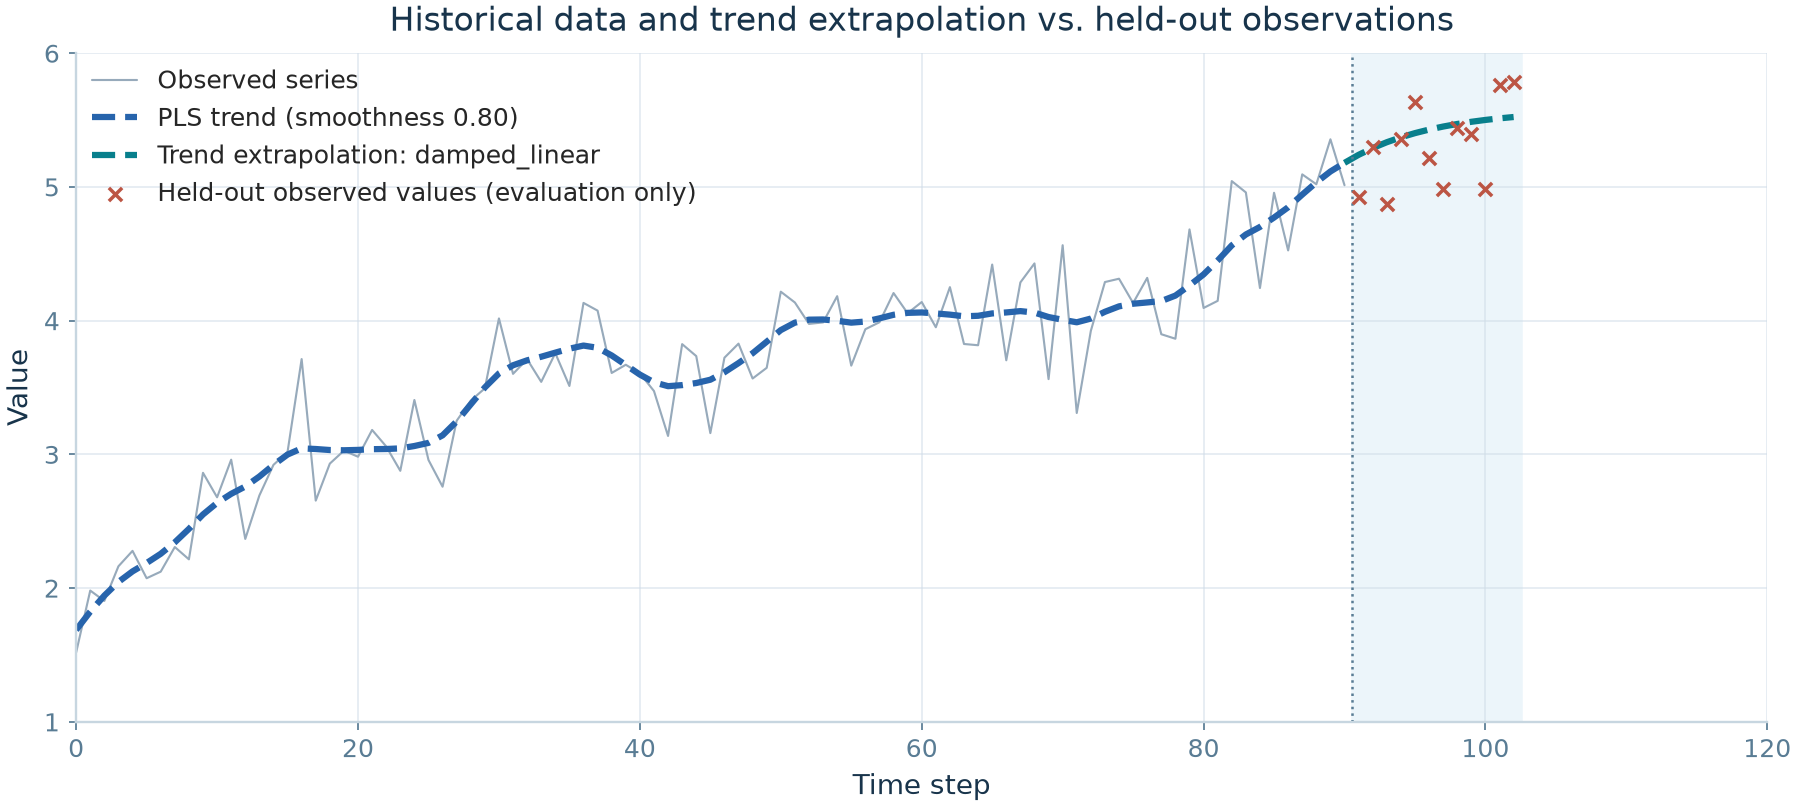

In [5]:
forecast_ax = plot_forecast(result)
forecast_ax.scatter(result.future_index, test, s=28, marker="x",
                    color="#bc5544", linewidth=1.4,
                    label="Held-out observed values (evaluation only)", zorder=8)
forecast_ax.legend(frameon=False)
forecast_ax.set_title("Historical data and trend extrapolation vs. held-out observations")
if SAVE_SVG:
    FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
    forecast_ax.figure.savefig(FIGURE_DIRECTORY / "01-forecast-vs-actual.svg",
                               dpi=180, facecolor="white")
plt.show()

## 4. Plot 2 — compare fixed smoothing levels

Use the *same historical data* and difference order to overlay smoothing targets of 0.20, 0.50, 0.80 and 0.95. The purpose is to understand how changing the smoothness target affects the **in-sample trend**, not to infer which level predicts the future best.

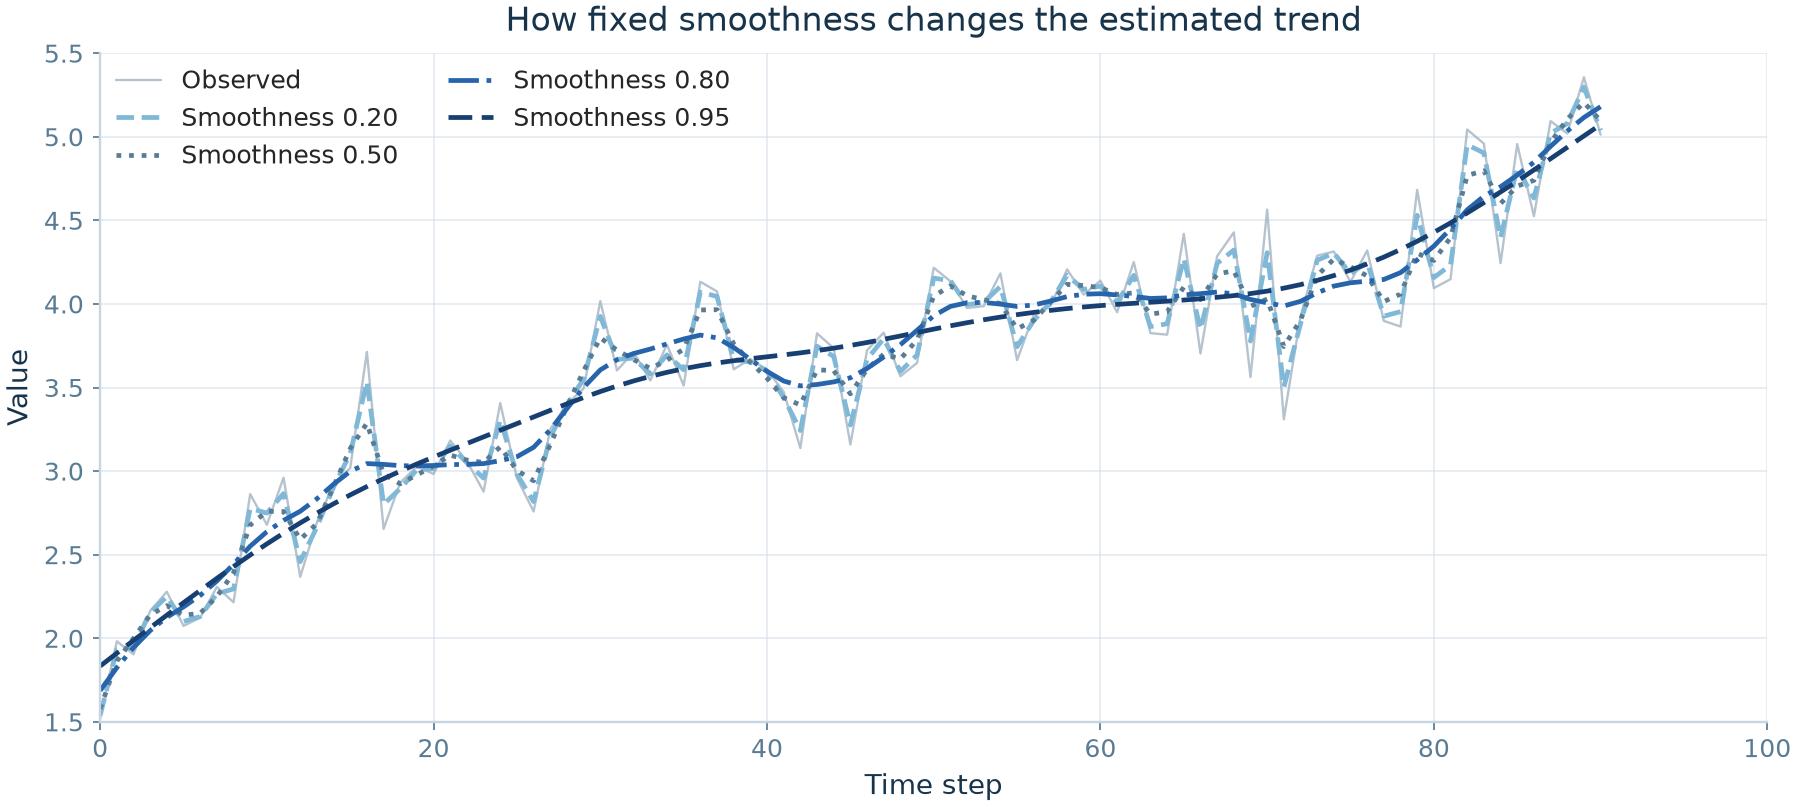

In [6]:
ax = plot_smoothness_comparison(
    history, order=ORDER, mu=0.0, smoothness_levels=(0.20, 0.50, 0.80, 0.95),
)
if SAVE_SVG:
    ax.figure.savefig(FIGURE_DIRECTORY / "02-smoothness-comparison.svg",
                      dpi=180, facecolor="white")
plt.show()

## 5. Plot 3 — map smoothness to the penalty

For the chosen differencing order, smoothness is monotonically related to the penalty $\lambda$. This chart shows why requesting 0.80 is a deterministic specification and not a forecasting-validation decision.

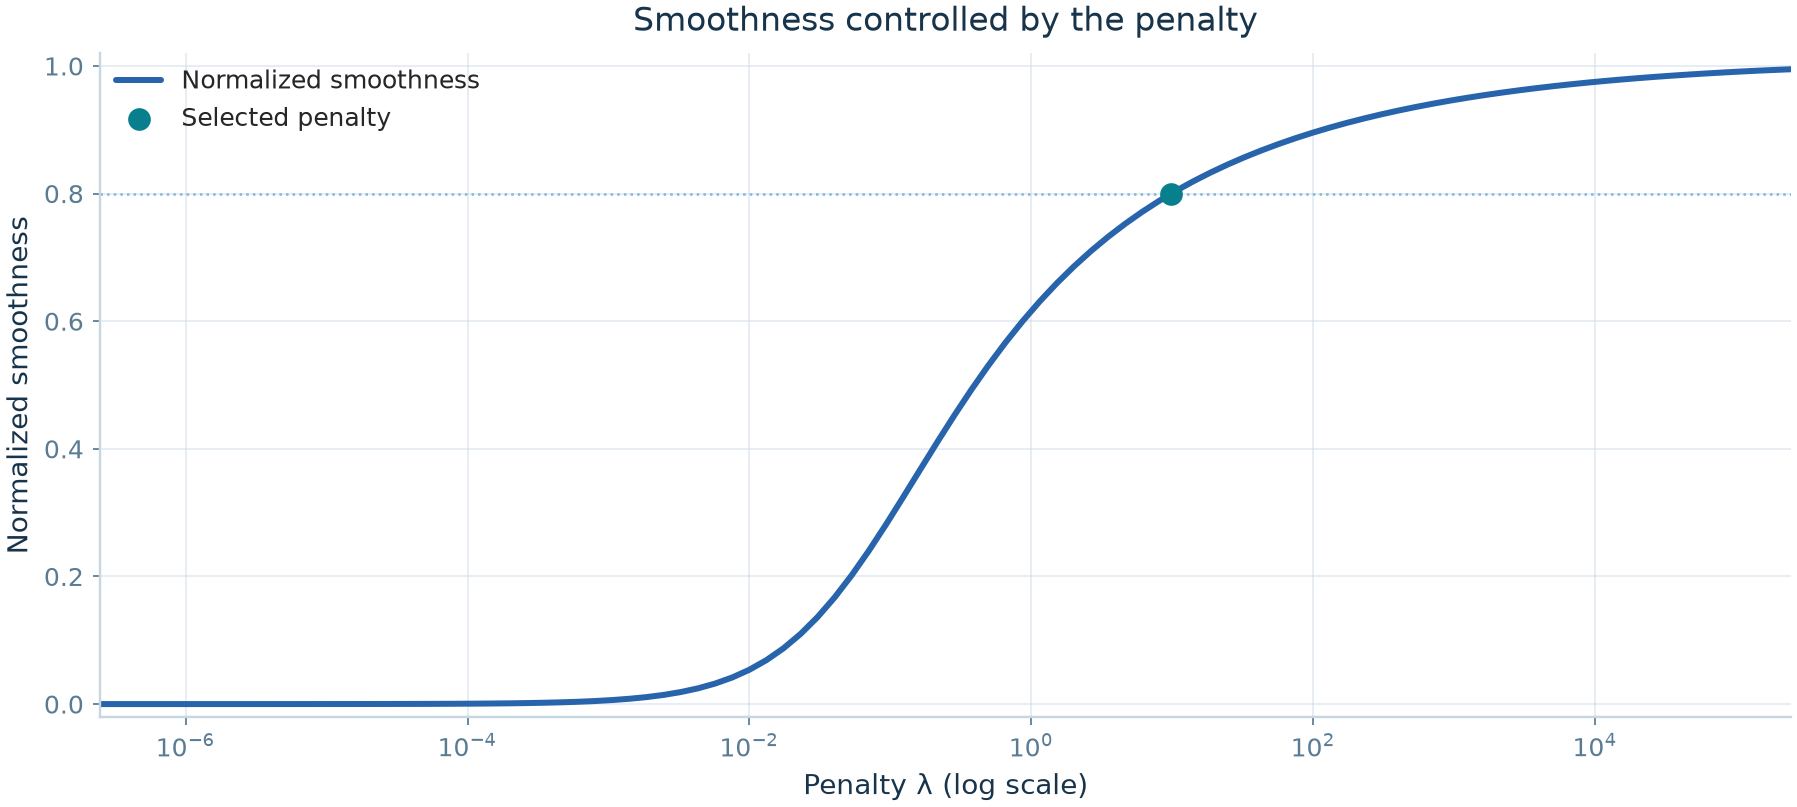

In [7]:
ax = plot_smoothness_path(result)
if SAVE_SVG:
    ax.figure.savefig(FIGURE_DIRECTORY / "03-smoothness-path.svg",
                      dpi=180, facecolor="white")
plt.show()

## 6. Plot 4 — three extrapolation assumptions

We compare **last-value**, **local-linear**, and **damped-linear** continuation. These share the same historical smoothing assumptions, but extrapolate the end of the fitted trend differently.

No prediction intervals are implied. We can inspect their trajectories before measuring performance on the separate withheld segment.

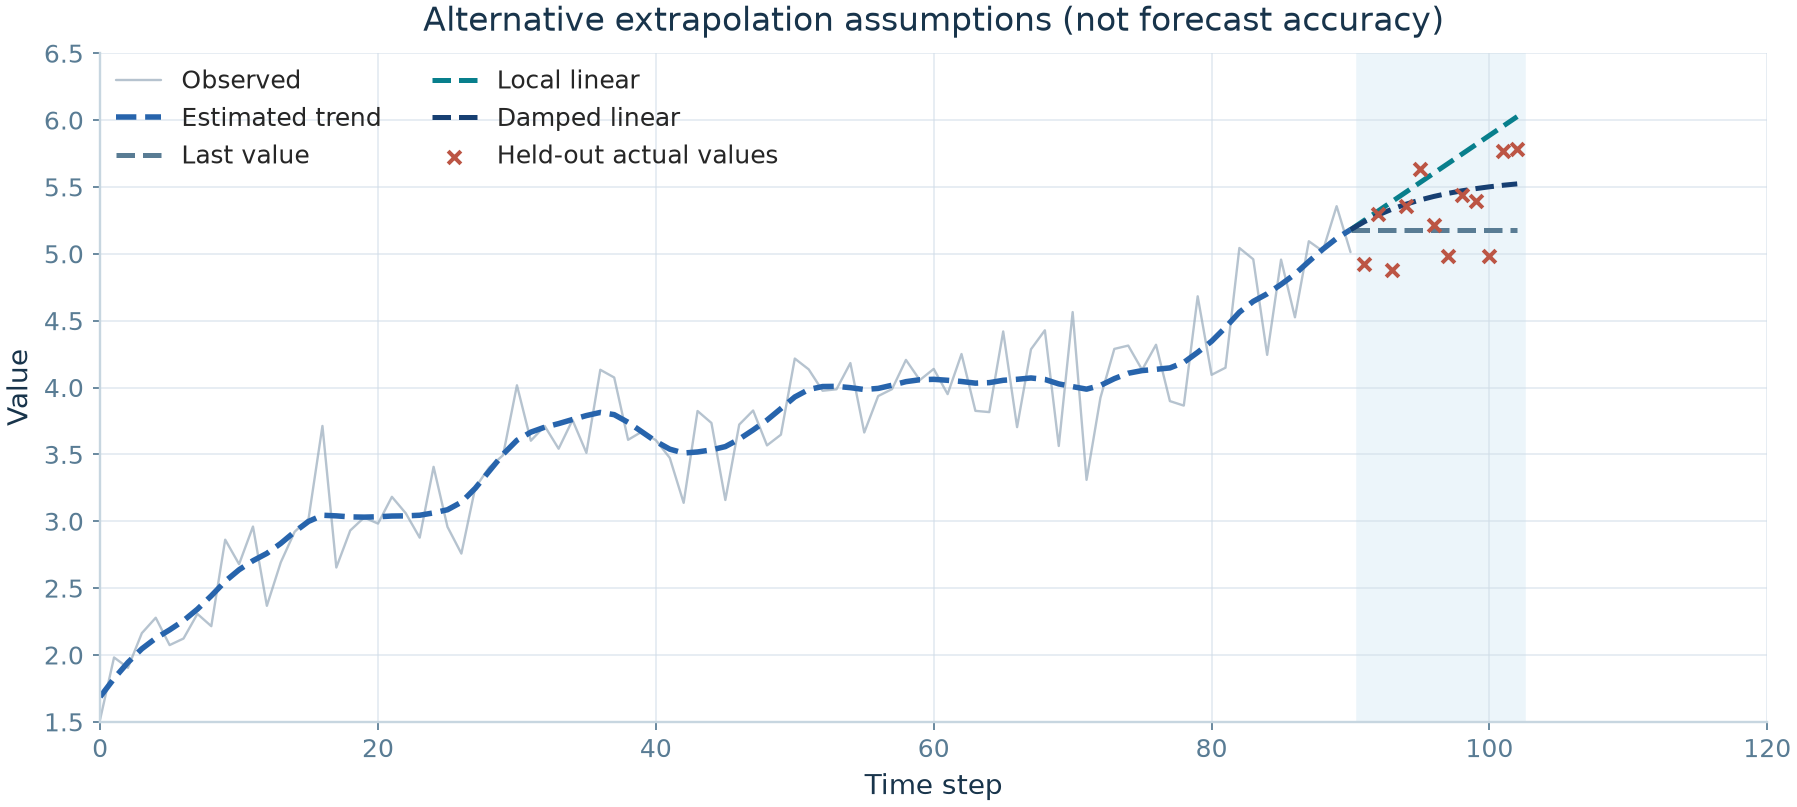

In [8]:
ax = plot_forecast_methods(result, damping=DAMPING)
ax.scatter(result.future_index, test, color="#bc5544", marker="x", s=26,
           label="Held-out actual values", zorder=8)
ax.legend(frameon=False,  ncol=2)
if SAVE_SVG:
    ax.figure.savefig(FIGURE_DIRECTORY / "04-methods.svg",
                      dpi=180, facecolor="white")
plt.show()

## 7. A genuine one-split forecast-error comparison

Compute the forecast once per extrapolation rule using **history only**. Calculate MAE and RMSE on the untouched final observations; include a naive last-observation random walk as a baseline.

This is a valid *single* holdout exercise, but it cannot establish robust forecasting superiority. A research-grade comparison would add many rolling origins, horizons and diverse data-generating processes.

METHOD                         MAE         RMSE
last_value                     0.28309     0.33026
local_linear                   0.35101     0.42786
damped_linear                  0.23893     0.29396
last_observation_baseline      0.33887     0.42287


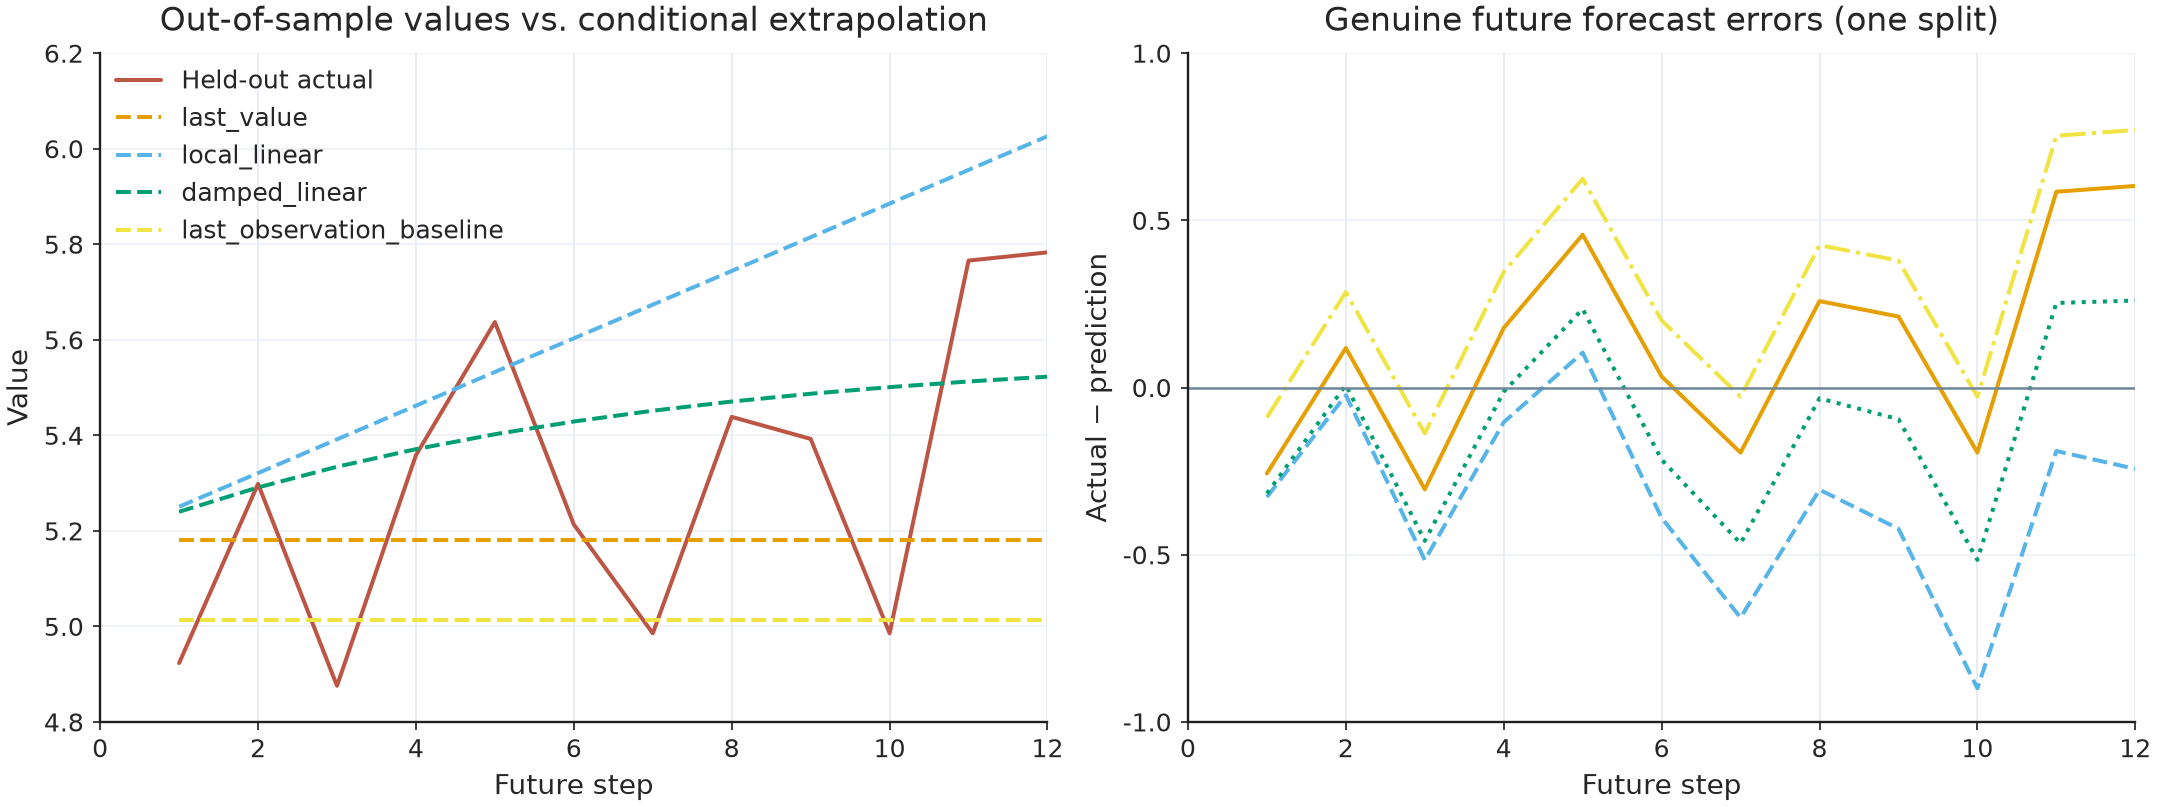

In [9]:
methods = ("last_value", "local_linear", "damped_linear")
predictions = {}
for name in methods:
    predictions[name] = forecast_trend(
        history, horizon=evaluation_steps, smoothness=SMOOTHNESS,
        order=ORDER, window=WINDOW, method=name, damping=DAMPING,
    ).forecast
predictions["last_observation_baseline"] = np.repeat(history[-1], evaluation_steps)

def errors(actual, predicted):
    error = np.asarray(actual) - np.asarray(predicted)
    return float(np.mean(np.abs(error))), float(np.sqrt(np.mean(error**2)))

print("METHOD                         MAE         RMSE")
for name, predicted in predictions.items():
    mae, rmse = errors(test, predicted)
    print(f"{name:<28} {mae:>9.5f}   {rmse:>9.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
step = np.arange(1, evaluation_steps + 1)
axes[0].plot(step, test, "-", color="#bc5544", label="Held-out actual")
palette = tuple(af.color_palette("okabe-ito", as_hex=True)[:4])
for (name, predicted), color in zip(predictions.items(), palette):
    axes[0].plot(step, predicted, "--", color=color, label=name)
axes[0].set(xlabel="Future step", ylabel="Value",
            title="Out-of-sample values vs. conditional extrapolation")
axes[0].legend(frameon=False)
for (name, predicted), color in zip(predictions.items(), palette):
    axes[1].plot(step, test - predicted, color=color, label=name)
axes[1].axhline(0, color="#708699", lw=1)
axes[1].set(xlabel="Future step", ylabel="Actual − prediction",
            title="Genuine future forecast errors (one split)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e7edf4", alpha=.8)
if SAVE_SVG:
    fig.savefig(FIGURE_DIRECTORY / "05-heldout-validation.svg",
                dpi=180, facecolor="white")
plt.show()

## 8. Plot 5 — descriptive diagnostics on historical fit

These are **in-sample residuals**, not the future forecast errors shown above. Inspect the residual path, histogram, normal Q–Q plot, and sample autocorrelation. A smooth curve can fit its history well while extrapolating poorly.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


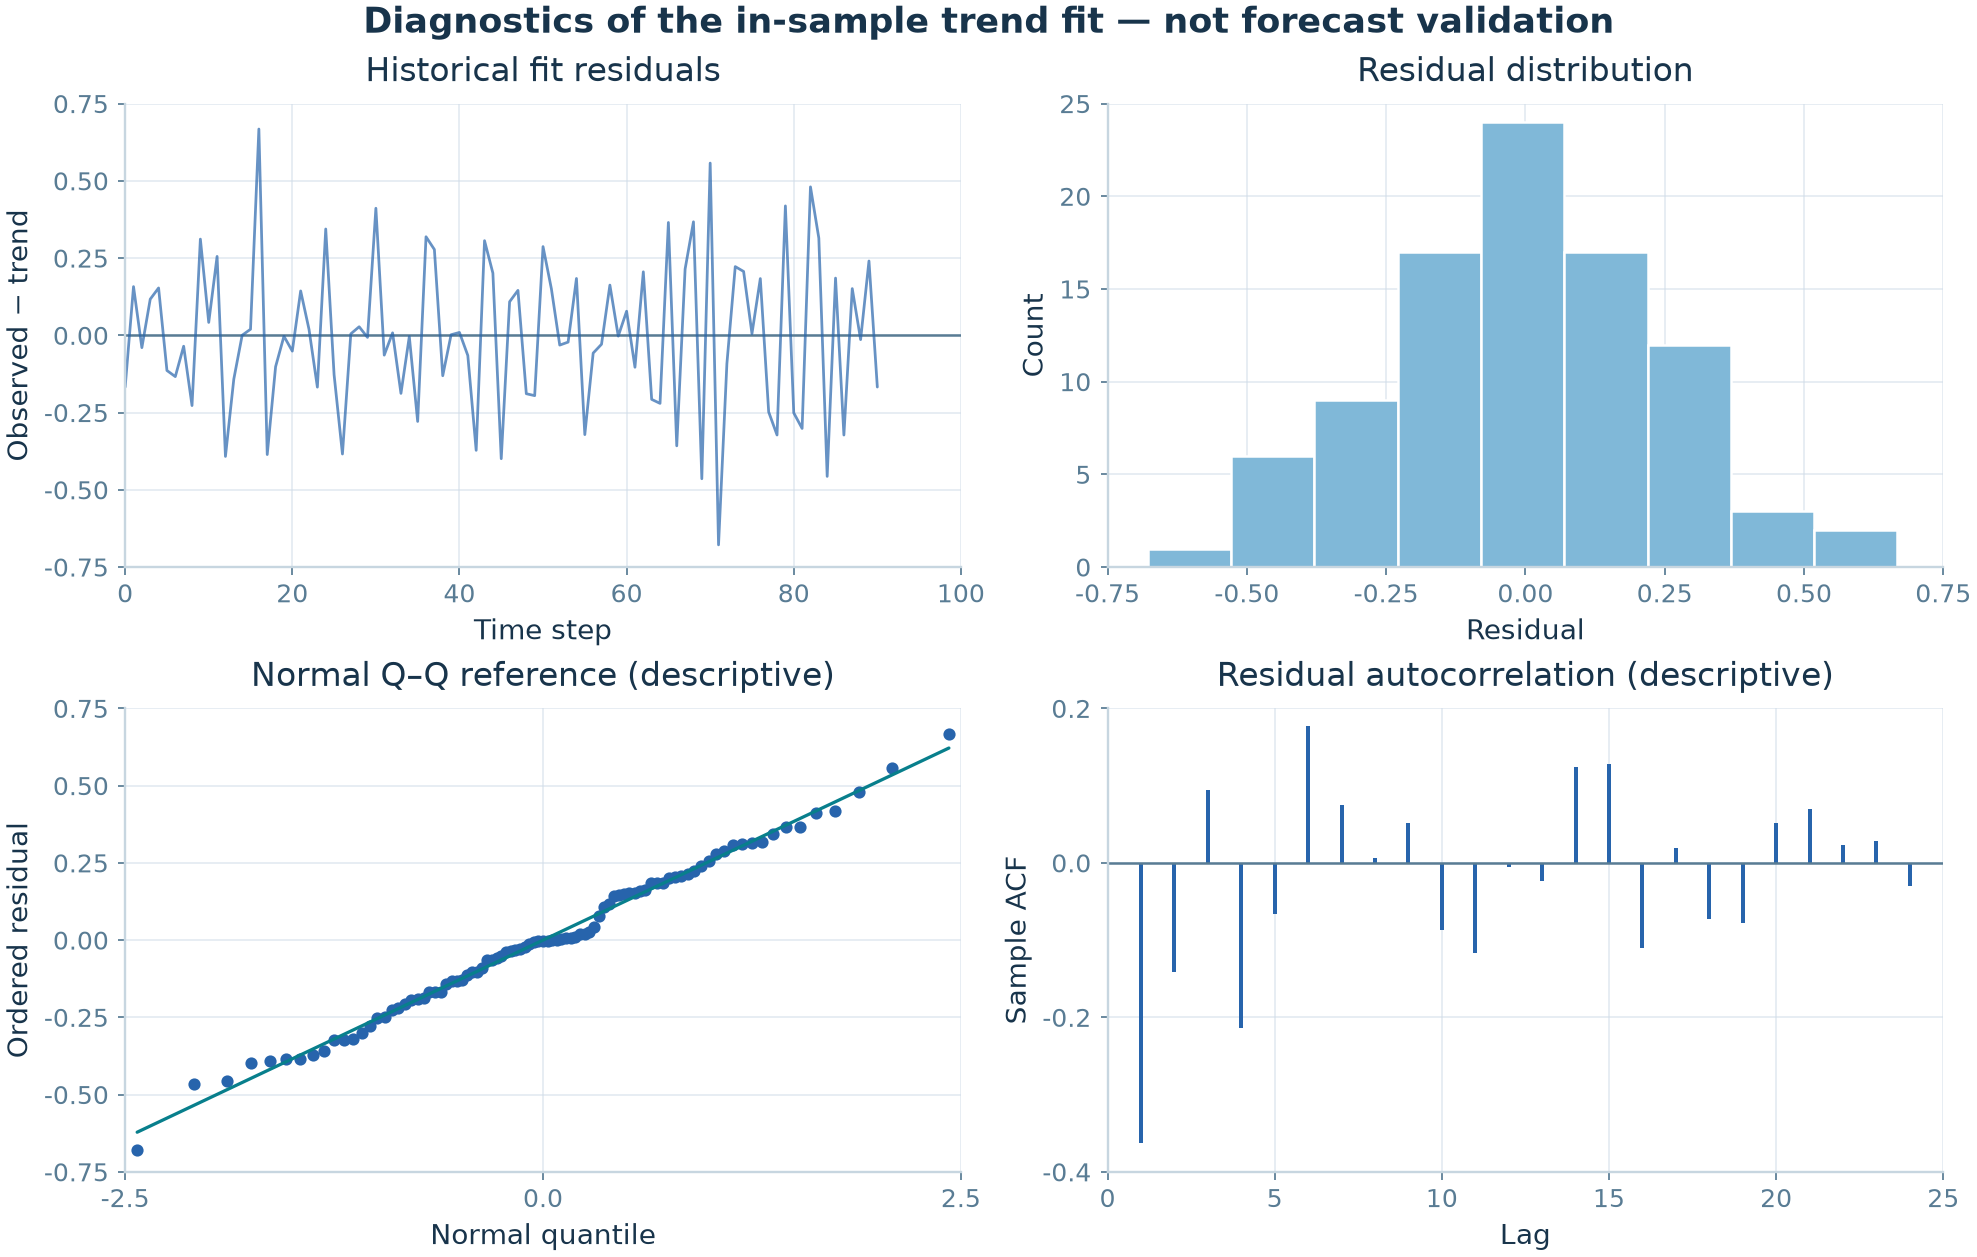

In [10]:
fig = plot_residual_diagnostics(result)
if SAVE_SVG:
    fig.savefig(FIGURE_DIRECTORY / "06-residual-diagnostics.svg",
                dpi=180, facecolor="white")
plt.show()

## 9. Plot 6 — integrated six-panel dashboard

The dashboard brings together the observed series and forecast, extrapolation assumptions, historical residuals, estimated trend differences, and smoothness mapping in one figure. It contains **no calibrated uncertainty intervals**.

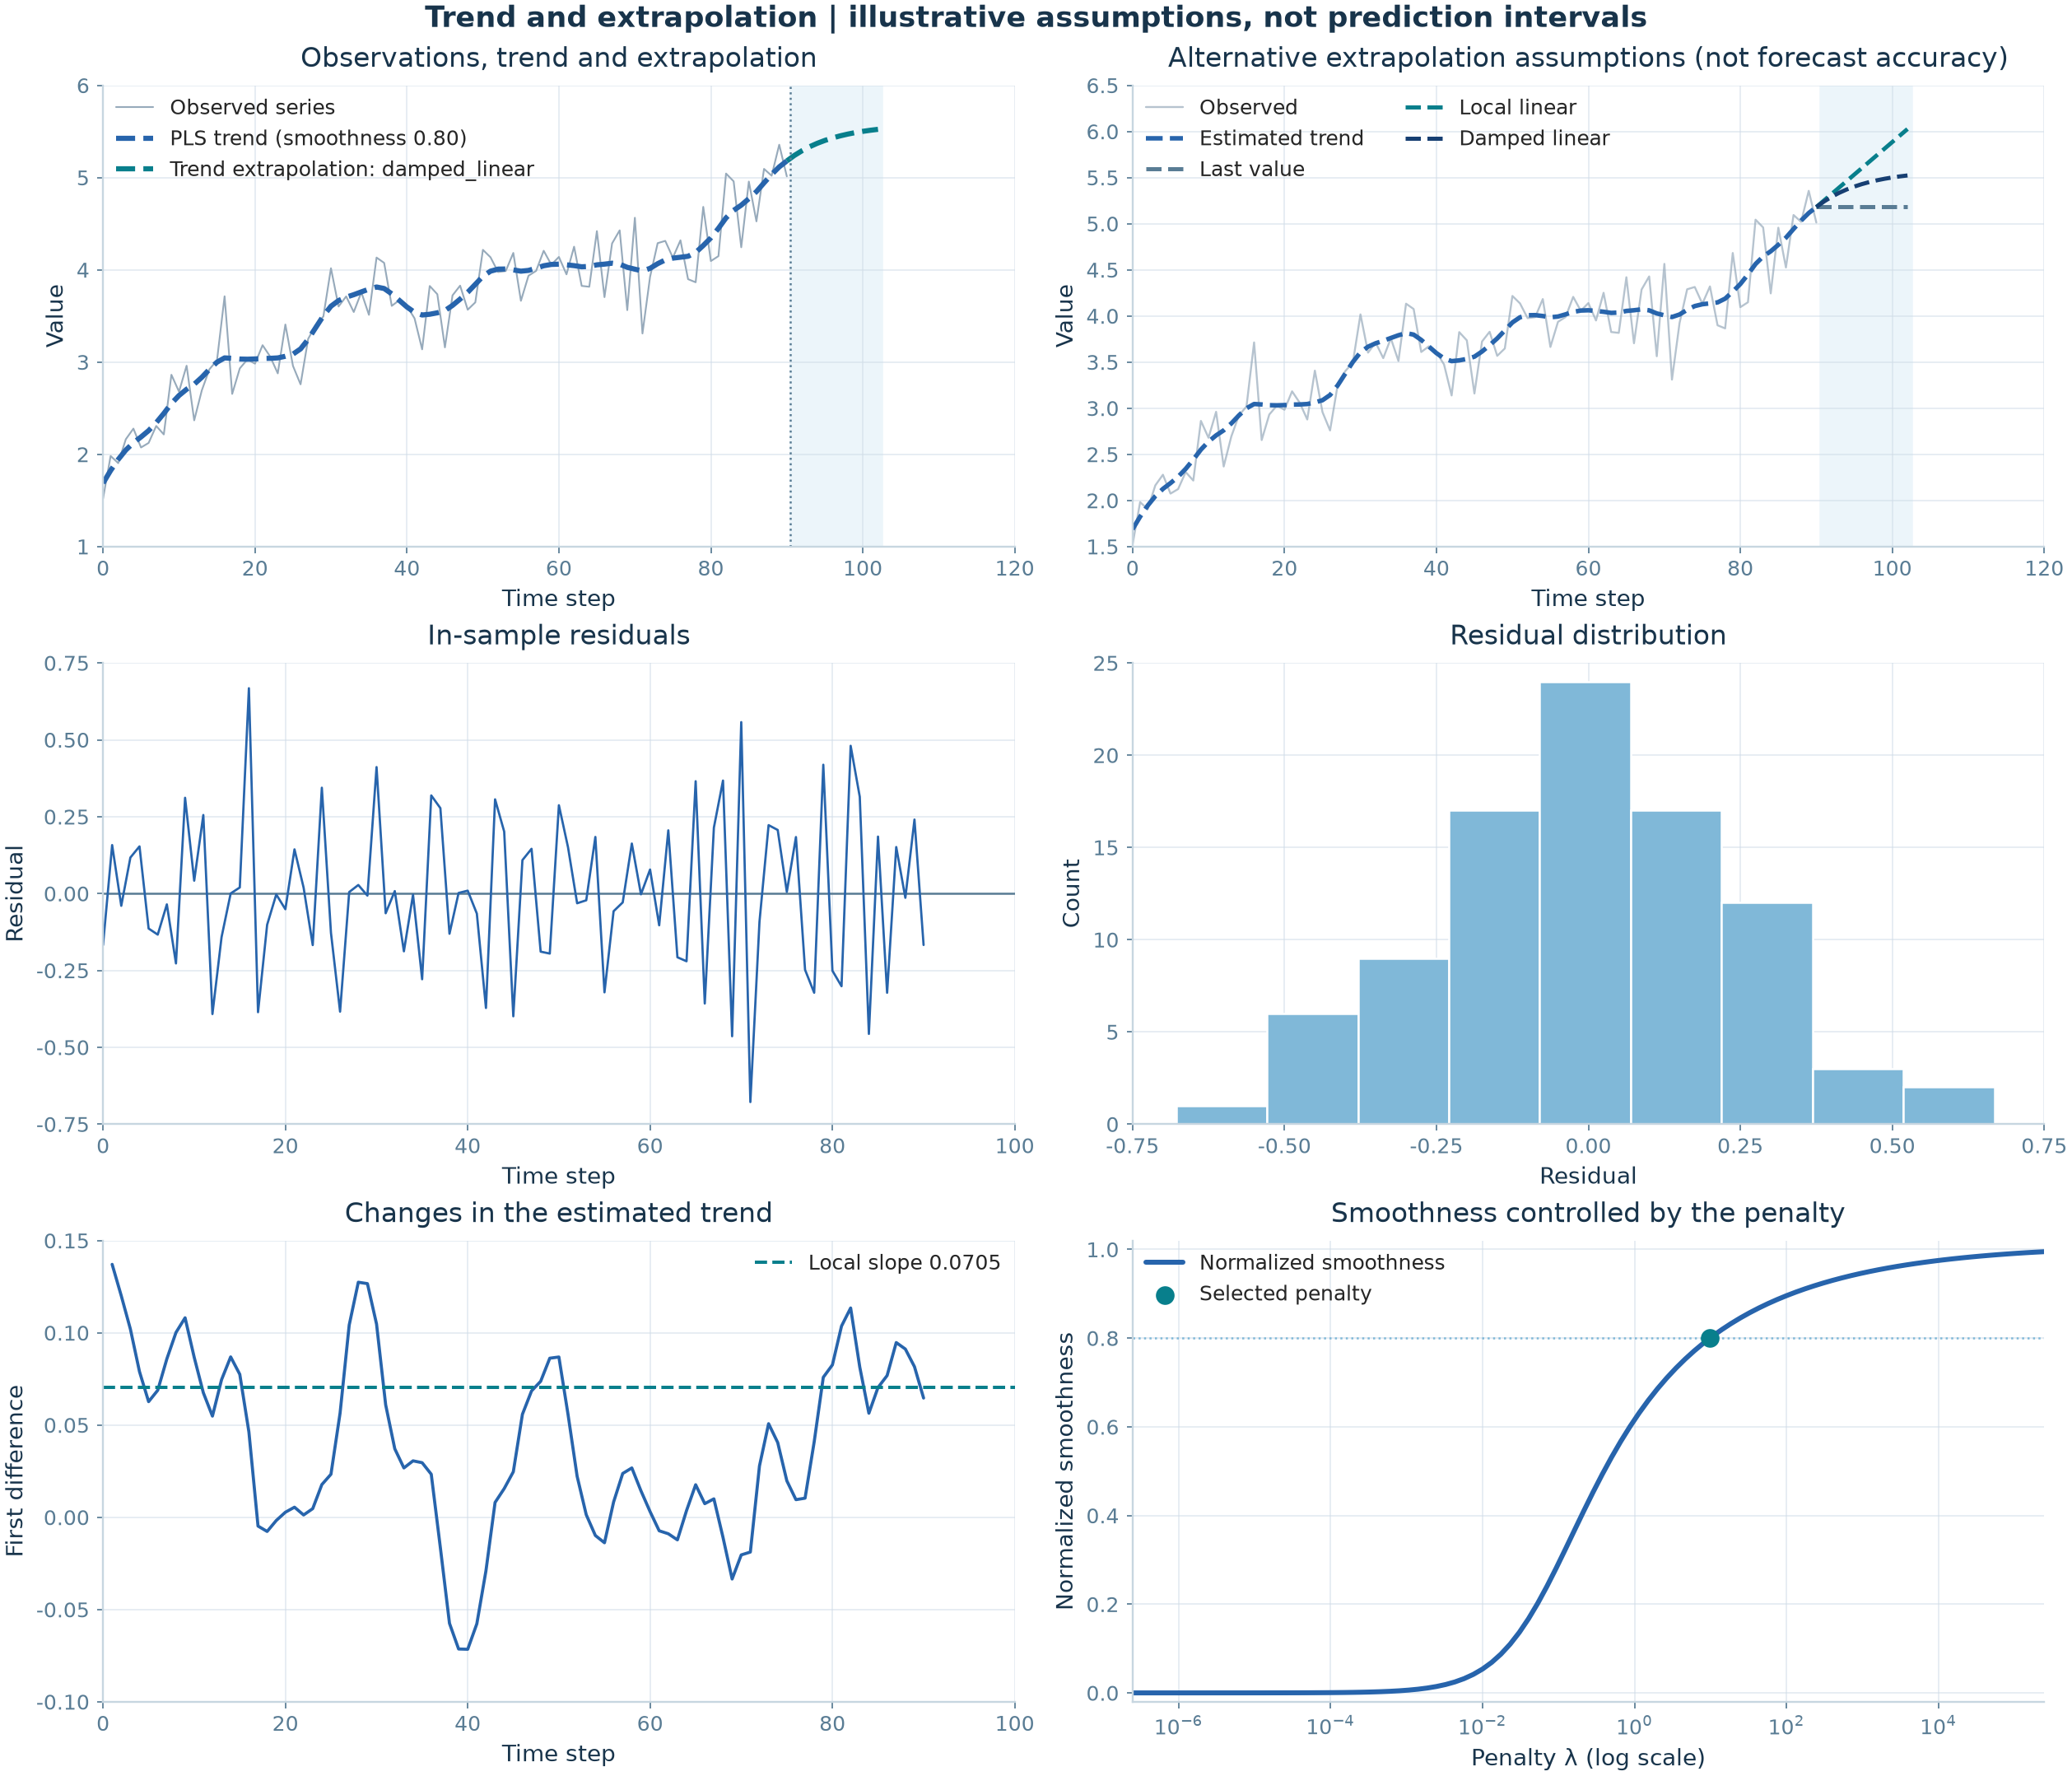

In [11]:
fig = plot_forecast_dashboard(result)
if SAVE_SVG:
    fig.savefig(FIGURE_DIRECTORY / "07-full-dashboard.svg",
                dpi=180, facecolor="white")
plt.show()

## 10. What we learned and how to extend the pipeline

- **History-only estimation:** The held-out observations were not passed to `forecast_trend`; the smoothing target is fixed before inspecting them.
- **0.8 means smoothness:** The normalized trace-based index controls trend flexibility, not prediction coverage or accuracy.
- **Three conditional rules:** Extrapolation depends on an explicit assumption about local slope persistence; different methods can diverge sharply.
- **Two error concepts:** Historical fit residuals measure in-sample mismatch; the holdout MAE/RMSE measure a small sample of future errors. Do not mix them.
- **Next validation stage:** Use multiple chronological rolling origins, report results by horizon, and compare against simple baselines before claiming useful forecasting skill.
- **Reproducing plots:** Set `SAVE_SVG=True` to save scalable SVGs to `build/forecast-notebook-figures/`. This optional export runs only when you execute the notebook; it does not commit generated figures.

**API reference:** `trendestimation.forecast_trend`, `plot_forecast`, `plot_smoothness_comparison`, `plot_smoothness_path`, `plot_forecast_methods`, `plot_residual_diagnostics`, and `plot_forecast_dashboard`.

## Matched penalty and smoothness score plots

For the current notebook data (or a labeled synthetic fallback), compare CV, GCV, AICc and BIC versus $\lambda$ **and** $S(\lambda)$; the mapped grids have identical candidate penalties. Each execution saves inline SVG and PNG figures. The single GCV selector timing is illustrative and is **not** a controlled speed comparison; use the separate multi-seed benchmark for that.

Paired penalty and smoothness: last 60 points of the notebook series; n=60, d=2, mu=0


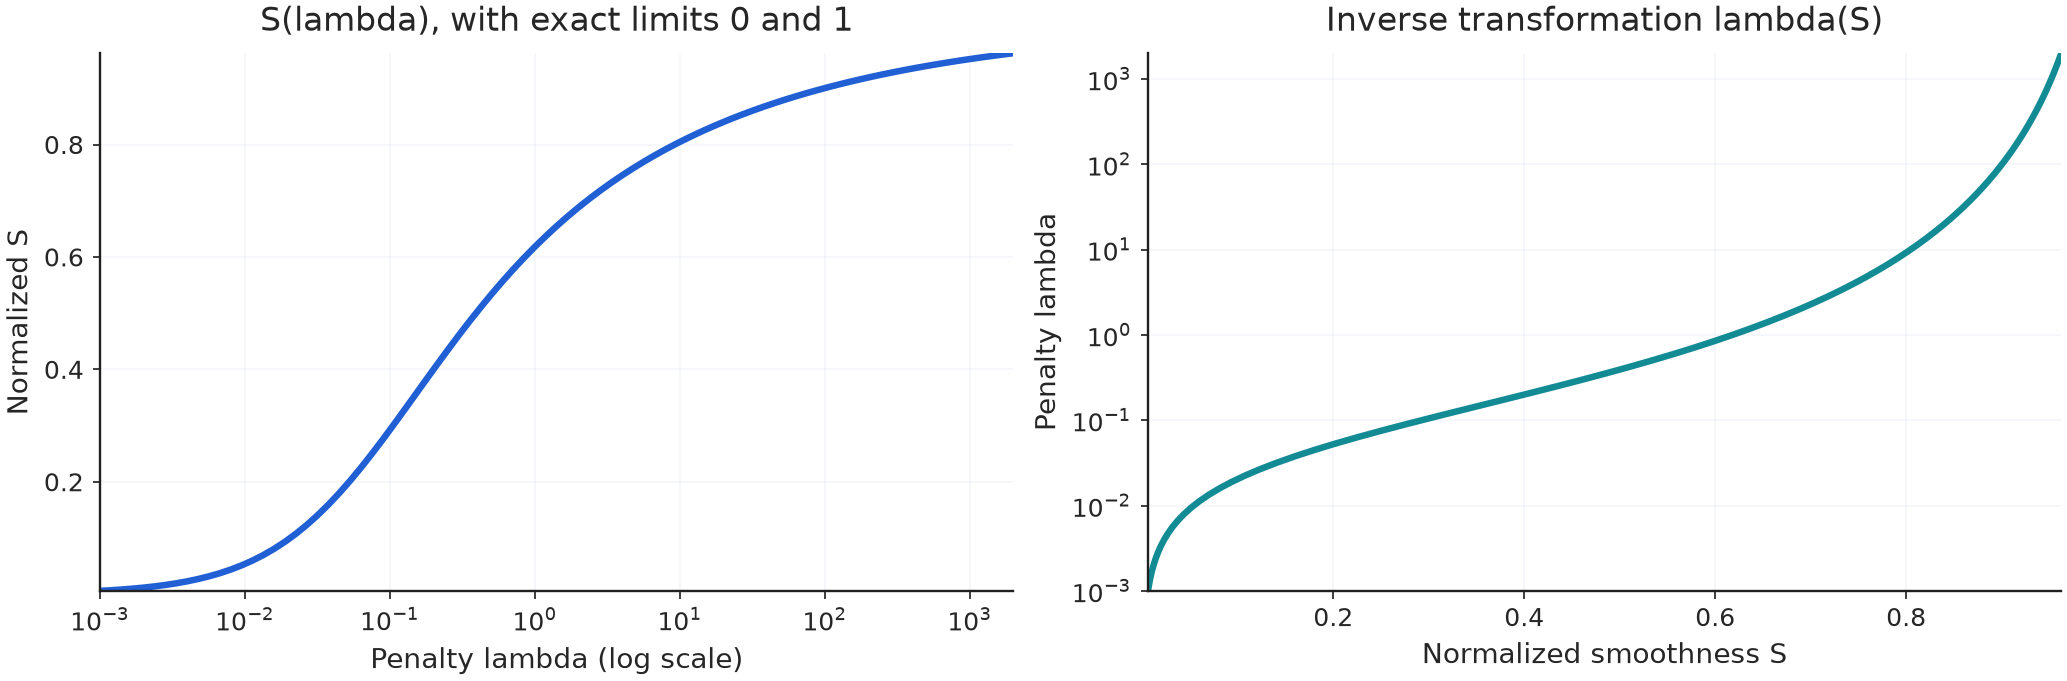

CV: selected lambda=502.26, S=0.93965, score=0.0955473
GCV: selected lambda=502.26, S=0.93965, score=0.0974316
AICC: selected lambda=596.96, S=0.94296, score=-2.29328
BIC: selected lambda=0.001, S=0.00593, score=-7.80541


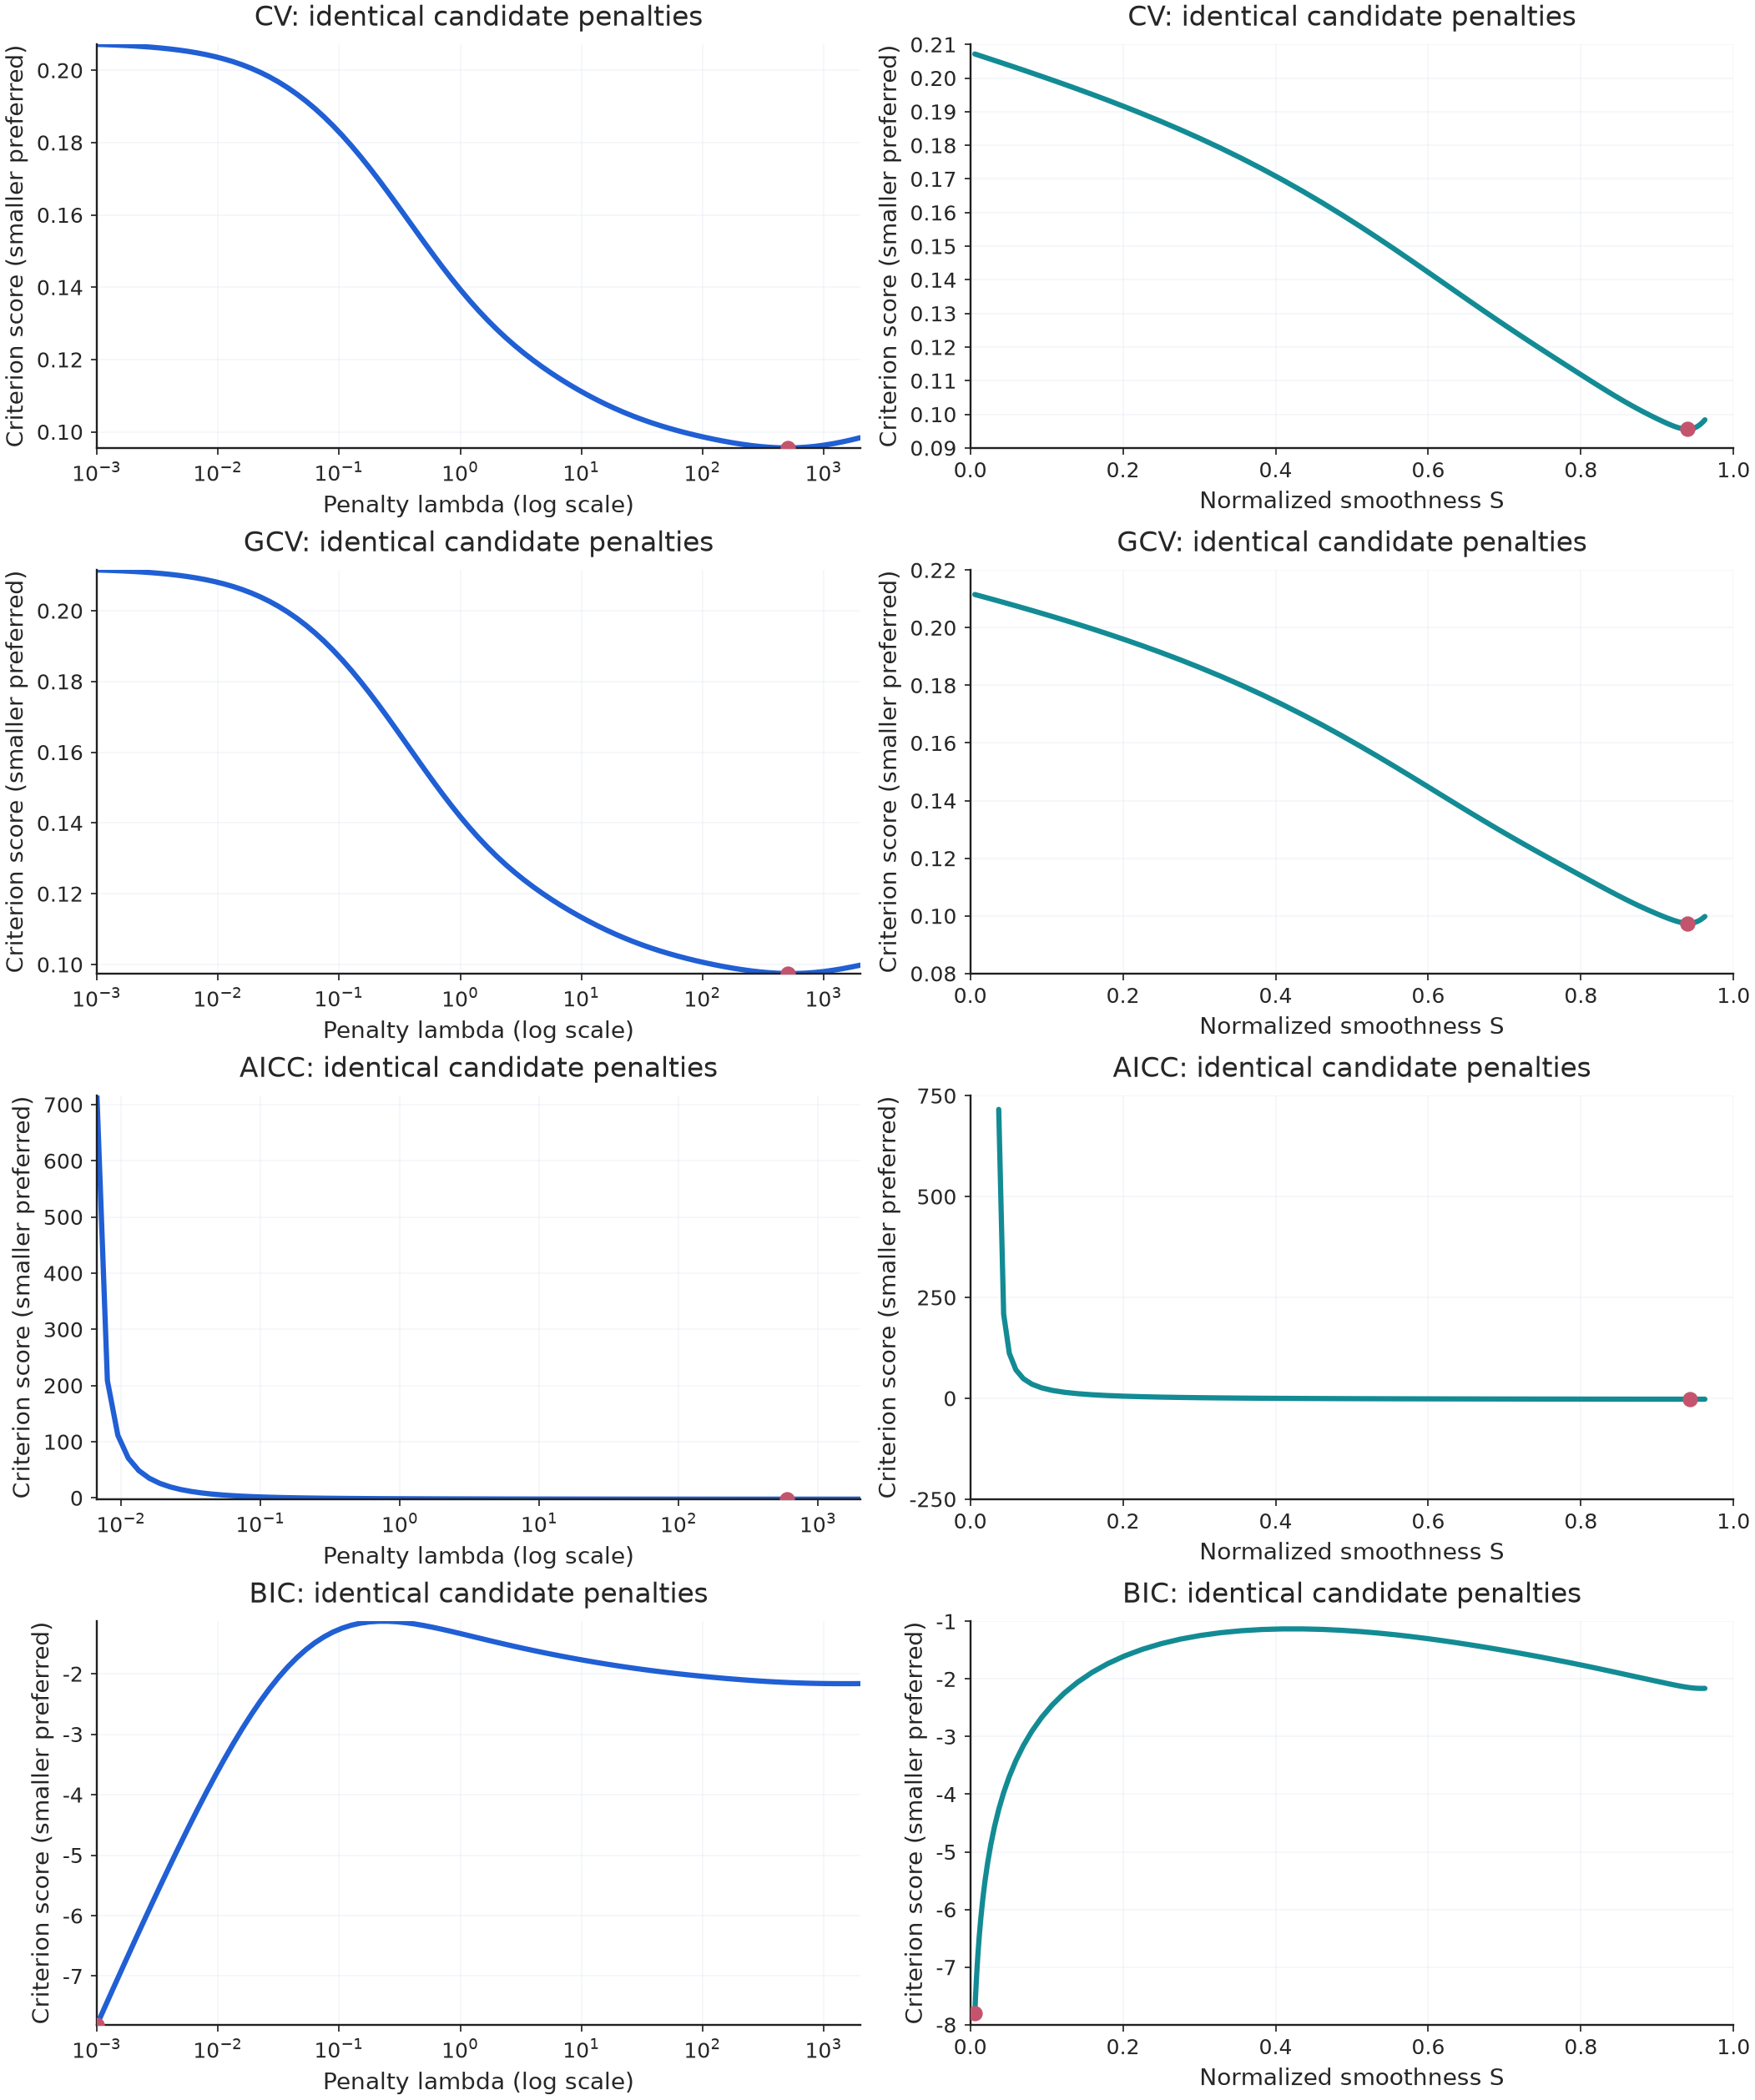

GCV lambda auto-search: 1.915 ms, lambda=489.81, S=0.93916, score=0.097437, candidates=122
GCV smoothness auto-search: 23.000 ms, lambda=557.43, S=0.94167, score=0.0974286, candidates=125


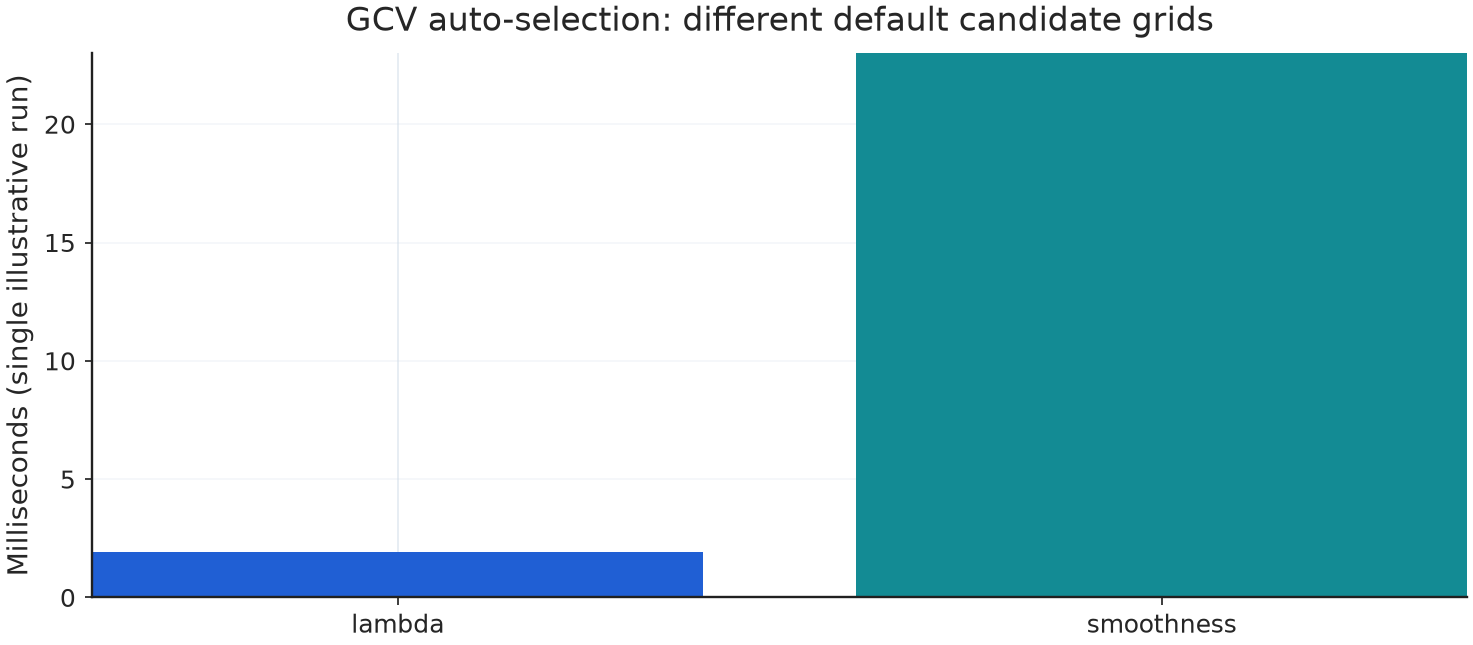

Timing is descriptive, not a controlled speed ranking. See the factorial and public API benchmarks for paired repetitions.


In [12]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
